# NeuroCheck: stroke risk analysis

This notebook explores the data, explains a hidden problem in it (near-duplicate stroke rows), and shows why the final model is a calibrated logistic regression.

The production training code is in `train.py`. This notebook is the story behind it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
RED, GREY, INK = "#E5484D", "#CBD5E1", "#101418"

df = pd.read_csv("data/brain_stroke.csv")
print(df.shape)
df.head()

(5140, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


## 1. The target is very imbalanced

In [2]:
rate = df.stroke.mean()
print(f"Stroke: {df.stroke.sum()} of {len(df)} ({rate:.1%})")
print(f"A model that always says 'no stroke' is {1-rate:.1%} accurate, so accuracy is the wrong metric here.")

Stroke: 407 of 5140 (7.9%)
A model that always says 'no stroke' is 92.1% accurate, so accuracy is the wrong metric here.


## 2. Risk by age, glucose and conditions

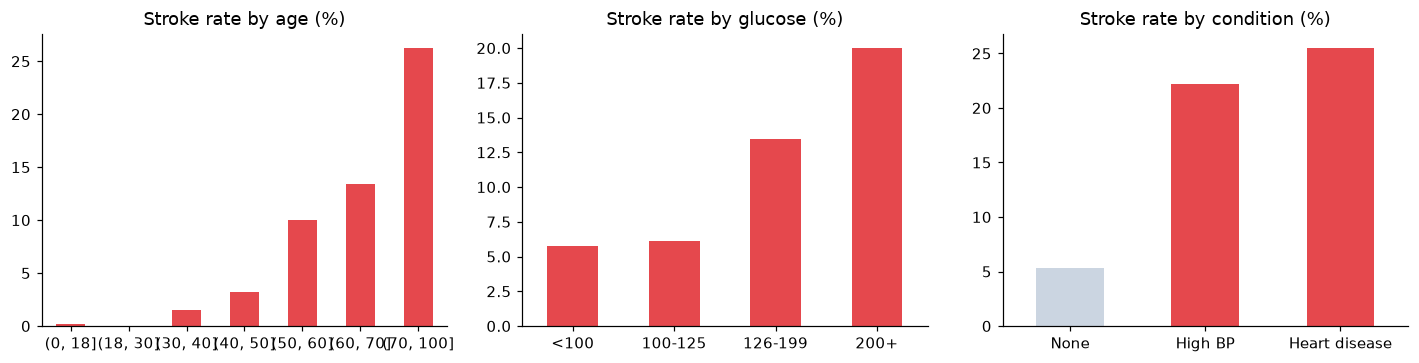

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
bins = pd.cut(df.age, [0, 18, 30, 40, 50, 60, 70, 100])
df.groupby(bins, observed=True).stroke.mean().mul(100).plot.bar(ax=ax[0], color=RED); ax[0].set_title("Stroke rate by age (%)"); ax[0].set_xlabel("")
g = pd.cut(df.avg_glucose_level, [0, 100, 126, 200, 300], labels=["<100", "100-125", "126-199", "200+"])
df.groupby(g, observed=True).stroke.mean().mul(100).plot.bar(ax=ax[1], color=RED); ax[1].set_title("Stroke rate by glucose (%)"); ax[1].set_xlabel("")
cond = pd.Series({"None": df[(df.hypertension==0)&(df.heart_disease==0)].stroke.mean(),
                  "High BP": df[df.hypertension==1].stroke.mean(), "Heart disease": df[df.heart_disease==1].stroke.mean()}).mul(100)
cond.plot.bar(ax=ax[2], color=[GREY, RED, RED]); ax[2].set_title("Stroke rate by condition (%)")
for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout()

## 3. A hidden problem: near-copies of stroke patients

If stroke rows were real, independent patients, a stroke row's nearest neighbour should usually be a *non-stroke* row (92% of the data). Let's check.

In [4]:
NUM = ["age", "avg_glucose_level", "bmi"]
Z = pd.get_dummies(df.drop(columns="stroke"), dtype=float)
Z["bmi"] = Z["bmi"].fillna(Z["bmi"].median())
Z[NUM] = (Z[NUM] - Z[NUM].mean()) / Z[NUM].std()
dist, idx = NearestNeighbors(n_neighbors=2).fit(Z.values).kneighbors(Z.values)
y = df.stroke.values
same = (y[idx[:, 1]] == y)
print(f"Stroke rows whose nearest neighbour is ALSO a stroke row: {same[y==1].mean():.0%} (expected ~{y.mean():.0%} if independent)")
print(f"Median distance to nearest neighbour  stroke: {np.median(dist[y==1,1]):.3f}   non-stroke: {np.median(dist[y==0,1]):.3f}")

Stroke rows whose nearest neighbour is ALSO a stroke row: 77% (expected ~8% if independent)
Median distance to nearest neighbour  stroke: 0.156   non-stroke: 0.341


77% instead of ~8%, and stroke rows sit twice as close together even though there are far fewer of them. This is the fingerprint of **synthetic oversampling** (for example SMOTE) applied to the dataset *before* it was shared.

Grouping rows that are within a small distance of each other collapses the 407 stroke rows into about **246 distinct patients**, which matches the 249 stroke cases in the original public stroke dataset.

In [5]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import radius_neighbors_graph
G = radius_neighbors_graph(Z.values, radius=0.3, mode="connectivity").tocoo()
s = y == 1; keep = s[G.row] & s[G.col]
groups = connected_components(coo_matrix((np.ones(keep.sum()), (G.row[keep], G.col[keep])), shape=G.shape), directed=False)[1]
print("Distinct stroke patients:", len(set(groups[y == 1])))

Distinct stroke patients: 246


## 4. Why it matters: leaky testing rewards memorising

With normal cross-validation, a copy of a patient can be in the training fold while another copy is in the test fold. A model that memorises (like a fully-grown random forest) then looks great. `StratifiedGroupKFold` keeps every group on one side.

,normal CV,leak-safe CV
model,,
Logistic Regression,0.843,0.839
Random Forest (leaf=30),0.859,0.830
Random Forest (fully grown),0.907,0.786


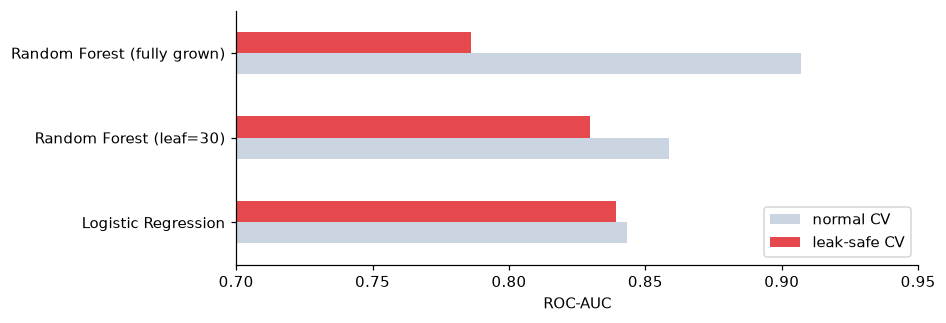

In [6]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

BIN = ["hypertension", "heart_disease"]; CAT = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
X = df[NUM + BIN + CAT]
lin = ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), NUM), ("bin", "passthrough", BIN), ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT)])
tree = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM), ("bin", "passthrough", BIN), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
models = {
    "Logistic Regression": Pipeline([("p", lin), ("m", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))]),
    "Random Forest (leaf=30)": Pipeline([("p", tree), ("m", RandomForestClassifier(300, min_samples_leaf=30, class_weight="balanced_subsample", n_jobs=-1, random_state=0))]),
    "Random Forest (fully grown)": Pipeline([("p", tree), ("m", RandomForestClassifier(300, min_samples_leaf=1, class_weight="balanced_subsample", n_jobs=-1, random_state=0))]),
}
rows = []
for name, m in models.items():
    a = roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1])
    b = roc_auc_score(y, cross_val_predict(m, X, y, groups=groups, cv=StratifiedGroupKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1])
    rows.append((name, a, b))
res = pd.DataFrame(rows, columns=["model", "normal CV", "leak-safe CV"]).set_index("model")
ax = res.plot.barh(color=[GREY, RED], figsize=(8, 3), xlim=(0.7, 0.95)); ax.set_xlabel("ROC-AUC"); ax.set_ylabel("")
res.round(3)

The fully-grown forest drops the most: it was recognising copies, not learning. Logistic regression barely moves, so its score is trustworthy, and across all models tried (see `train.py`) it is the best under leak-safe testing (~0.84).

## 5. The original project's 84% accuracy

The first version kept 400 non-stroke + 407 stroke rows and tested on 81 of them. Repeating that with different random splits shows how unstable an 81-row test is:

In [7]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import train_test_split
enc = {"gender": {"Female": 0, "Male": 1}, "ever_married": {"No": 0, "Yes": 1}, "work_type": {"children": 0, "Govt_job": 1, "Private": 2, "Self-employed": 3},
       "Residence_type": {"Rural": 0, "Urban": 1}, "smoking_status": {"formerly smoked": 0, "never smoked": 1, "smokes": 2, "Unknown": 3}}
old = pd.concat([df[df.stroke == 0].head(400), df[df.stroke == 1].head(407)]).dropna().replace(enc)
accs = []
for s_ in range(20):
    a, b, c, d = train_test_split(old.drop(columns="stroke"), old.stroke, stratify=old.stroke, test_size=0.1, random_state=s_)
    accs.append((ExtraTreesClassifier(15, random_state=42, max_features="log2").fit(a, c).predict(b) == d).mean())
print(f"Accuracy over 20 random 81-row tests: {min(accs):.0%} to {max(accs):.0%} (mean {np.mean(accs):.0%})")

Accuracy over 20 random 81-row tests: 74% to 89% (mean 83%)


## 6. Final model and calibration

`train.py` trains logistic regression with each group of copies weighted as one patient and without class balancing, so the output is a real probability. Calibration check from the saved metrics:

{'roc_auc': 0.84, 'pr_auc': 0.192, 'brier': 0.0429, 'recall_high': 0.801, 'specificity_high': 0.738}


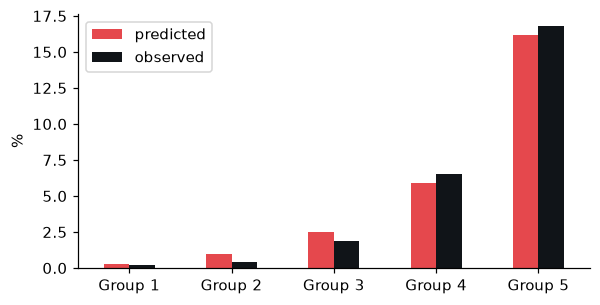

In [8]:
import json
m = json.load(open("../server/model/metrics.json"))
cal = pd.DataFrame(m["calibration"])
ax = cal.plot.bar(color=[RED, INK], figsize=(6, 3)); ax.set_xticklabels([f"Group {i+1}" for i in range(len(cal))], rotation=0); ax.set_ylabel("%")
print({k: m["final_model"][k] for k in ["roc_auc", "pr_auc", "brier", "recall_high", "specificity_high"]})

## Takeaways

- Accuracy is misleading on imbalanced medical data. Use ROC-AUC, recall and calibration.
- Always check a dataset for duplicates and synthetic rows **before** trusting cross-validation.
- After fixing the leak, the simplest model won, and it also gives exact, readable explanations for every prediction.